In [1]:

import pandas as pd

df = pd.read_csv('/content/winequality-red.csv', sep=';')

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\nColumn Names:")
print(df.columns.tolist())


Dataset loaded successfully!
Dataset Shape: (1599, 12)

First 5 rows:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  qual

In [2]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nQuality Score Counts:")
print(df["quality"].value_counts().sort_index())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

Missing Values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual s

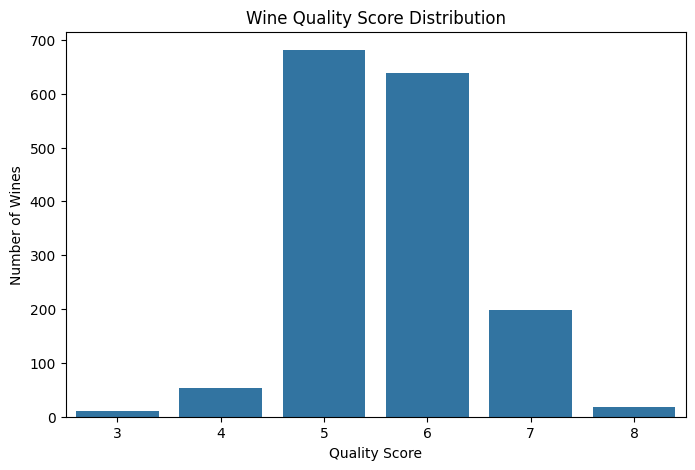

In [3]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="quality")
plt.title("Wine Quality Score Distribution")
plt.xlabel("Quality Score")
plt.ylabel("Number of Wines")
plt.show()


In [4]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop("quality", axis=1)
y = df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Data preparation completed!")


Training data shape: (1279, 11)
Testing data shape: (320, 11)
Data preparation completed!


In [5]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

lr_model = LogisticRegression(max_iter=2000)
lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

lr_accuracy = accuracy_score(y_test, lr_pred)

print("Logistic Regression Results")
print("Accuracy:", round(lr_accuracy * 100, 2), "%")


Logistic Regression Results
Accuracy: 59.06 %


In [6]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Results")
print("Accuracy:", round(dt_accuracy * 100, 2), "%")


Decision Tree Results
Accuracy: 60.94 %


In [7]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Results")
print("Accuracy:", round(rf_accuracy * 100, 2), "%")


Random Forest Results
Accuracy: 67.5 %


In [8]:

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy (%)": [
        round(lr_accuracy * 100, 2),
        round(dt_accuracy * 100, 2),
        round(rf_accuracy * 100, 2)
    ]
})

print(results.sort_values(
    by="Accuracy (%)", ascending=False
).to_string(index=False))


              Model  Accuracy (%)
      Random Forest         67.50
      Decision Tree         60.94
Logistic Regression         59.06


In [9]:

from sklearn.metrics import classification_report

print("LOGISTIC REGRESSION REPORT")
print(classification_report(y_test, lr_pred, zero_division=0))

print("\nDECISION TREE REPORT")
print(classification_report(y_test, dt_pred, zero_division=0))

print("\nRANDOM FOREST REPORT")
print(classification_report(y_test, rf_pred, zero_division=0))


LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.62      0.73      0.67       136
           6       0.54      0.61      0.57       128
           7       0.71      0.30      0.42        40
           8       0.00      0.00      0.00         3

    accuracy                           0.59       320
   macro avg       0.31      0.27      0.28       320
weighted avg       0.57      0.59      0.57       320


DECISION TREE REPORT
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.38      0.27      0.32        11
           5       0.70      0.69      0.69       136
           6       0.58      0.55      0.57       128
           7       0.55      0.65      0.60        40
           8       0.14      0.33      0.20         3

    accuracy                

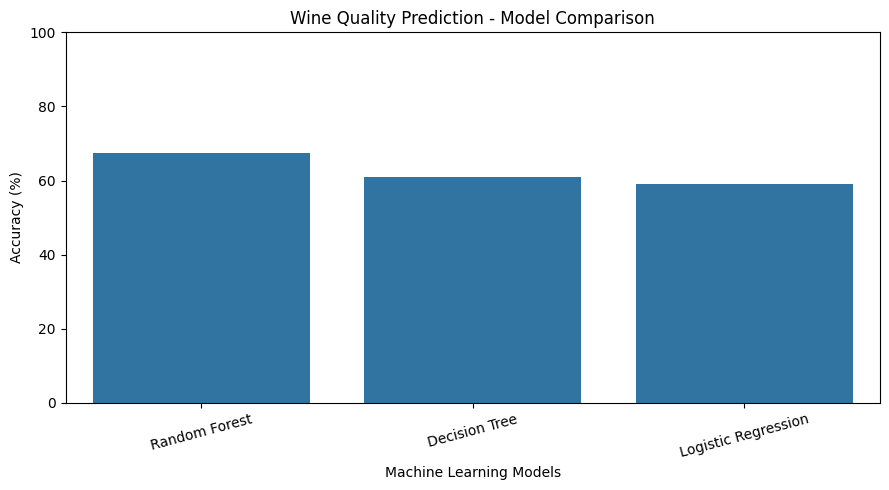

In [10]:

import matplotlib.pyplot as plt
import seaborn as sns

results_sorted = results.sort_values(
    by="Accuracy (%)", ascending=False
)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=results_sorted,
    x="Model",
    y="Accuracy (%)"
)

plt.title("Wine Quality Prediction - Model Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


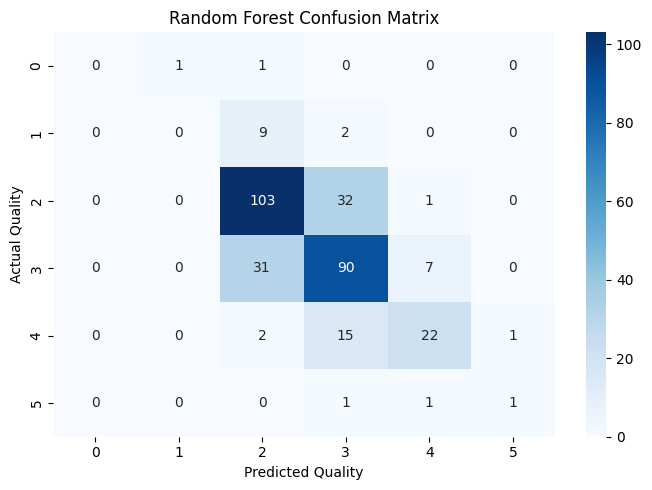

In [11]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

cm = confusion_matrix(y_test, rf_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Quality")
plt.ylabel("Actual Quality")
plt.tight_layout()
plt.show()


In [12]:

print("WINE QUALITY PREDICTION")
print("=" * 35)

print("\nModel Accuracy Comparison:")
print(results.sort_values(
    by="Accuracy (%)", ascending=False
).to_string(index=False))

best_model_name = results.loc[
    results["Accuracy (%)"].idxmax(), "Model"
]

print("\nBest Model:", best_model_name)

print("\nConclusion:")
print("Wine quality was predicted using chemical properties.")
print("Three classification models were compared.")
print("The model with the highest accuracy performed best")
print("on this test dataset.")


WINE QUALITY PREDICTION

Model Accuracy Comparison:
              Model  Accuracy (%)
      Random Forest         67.50
      Decision Tree         60.94
Logistic Regression         59.06

Best Model: Random Forest

Conclusion:
Wine quality was predicted using chemical properties.
Three classification models were compared.
The model with the highest accuracy performed best
on this test dataset.
